# COPD Mortality in Thailand: Trend Forecasting and Provincial Risk Classification

Province-level COPD mortality rates for 2019-2023 (B.E. 2562-2566): ANOVA tests, a per-province linear-regression forecast for 2024 (B.E. 2567) and a KNN risk-level classifier.

## Step 1: Data cleaning and time-series transformation

In [ ]:
import pandas as pd


file_path = 'data/จำนวนและอัตราตายด้วย5โรคNCD25622566.xlsx'

df = pd.read_excel(file_path, sheet_name='ทางเดินหายใจอุดกั้นเรื้อรัง', skiprows=5, header=None)

cols_to_keep = [0, 1, 3, 6, 9, 12, 15]
df = df[cols_to_keep]
df.columns = ['Health_Zone', 'Province', '2562', '2563', '2564', '2565', '2566']

df = df.dropna(subset=['Province'])
df = df[df['Province'] != 'ทั้งประเทศ']
df = df[~df['Province'].str.contains('รวม', na=False)]
df['Province'] = df['Province'].str.strip()

df_zones = df[['Province', 'Health_Zone']].copy()
df_zones['Health_Zone'] = df_zones['Health_Zone'].fillna('13').astype(str)
df_zones['Health_Zone'] = df_zones['Health_Zone'].str.replace(r'\.0', '', regex=True)

province_en_dict = {
    'กรุงเทพมหานคร': 'Bangkok', 'กำแพงเพชร': 'Kamphaeng Phet', 'ชัยนาท': 'Chai Nat', 'นครนายก': 'Nakhon Nayok',
    'นครปฐม': 'Nakhon Pathom', 'นครสวรรค์': 'Nakhon Sawan', 'นนทบุรี': 'Nonthaburi', 'ปทุมธานี': 'Pathum Thani',
    'พระนครศรีอยุธยา': 'Phra Nakhon Si Ayutthaya', 'พิจิตร': 'Phichit', 'พิษณุโลก': 'Phitsanulok', 'เพชรบูรณ์': 'Phetchabun',
    'ลพบุรี': 'Lopburi', 'สมุทรปราการ': 'Samut Prakan', 'สมุทรสงคราม': 'Samut Songkhram', 'สมุทรสาคร': 'Samut Sakhon',
    'สิงห์บุรี': 'Sing Buri', 'สุโขทัย': 'Sukhothai', 'สุพรรณบุรี': 'Suphan Buri', 'สระบุรี': 'Saraburi',
    'อ่างทอง': 'Ang Thong', 'อุทัยธานี': 'Uthai Thani', 'เชียงใหม่': 'Chiang Mai', 'เชียงราย': 'Chiang Rai',
    'ลำปาง': 'Lampang', 'ลำพูน': 'Lamphun', 'แม่ฮ่องสอน': 'Mae Hong Son', 'พะเยา': 'Phayao', 'แพร่': 'Phrae',
    'น่าน': 'Nan', 'อุตรดิตถ์': 'Uttaradit', 'กาฬสินธุ์': 'Kalasin', 'ขอนแก่น': 'Khon Kaen', 'ชัยภูมิ': 'Chaiyaphum',
    'นครพนม': 'Nakhon Phanom', 'นครราชสีมา': 'Nakhon Ratchasima', 'บึงกาฬ': 'Bueng Kan', 'บุรีรัมย์': 'Buri Ram',
    'มหาสารคาม': 'Maha Sarakham', 'มุกดาหาร': 'Mukdahan', 'ยโสธร': 'Yasothon', 'ร้อยเอ็ด': 'Roi Et', 'เลย': 'Loei',
    'สกลนคร': 'Sakon Nakhon', 'สุรินทร์': 'Surin', 'ศรีสะเกษ': 'Si Sa Ket', 'หนองคาย': 'Nong Khai',
    'หนองบัวลำภู': 'Nong Bua Lam Phu', 'อุดรธานี': 'Udon Thani', 'อุบลราชธานี': 'Ubon Ratchathani', 'อำนาจเจริญ': 'Amnat Charoen',
    'จันทบุรี': 'Chanthaburi', 'ฉะเชิงเทรา': 'Chachoengsao', 'ชลบุรี': 'Chonburi', 'ตราด': 'Trat',
    'ปราจีนบุรี': 'Prachinburi', 'ระยอง': 'Rayong', 'สระแก้ว': 'Sa Kaeo', 'กาญจนบุรี': 'Kanchanaburi', 'ตาก': 'Tak',
    'ประจวบคีรีขันธ์': 'Prachuap Khiri Khan', 'เพชรบุรี': 'Phetchaburi', 'ราชบุรี': 'Ratchaburi', 'กระบี่': 'Krabi',
    'ชุมพร': 'Chumphon', 'ตรัง': 'Trang', 'นครศรีธรรมราช': 'Nakhon Si Thammarat', 'นราธิวาส': 'Narathiwat',
    'ปัตตานี': 'Pattani', 'พังงา': 'Phang Nga', 'พัทลุง': 'Phatthalung', 'ภูเก็ต': 'Phuket', 'ยะลา': 'Yala',
    'ระนอง': 'Ranong', 'สงขลา': 'Songkhla', 'สตูล': 'Satun', 'สุราษฎร์ธานี': 'Surat Thani'
}

df_zones['Province'] = df_zones['Province'].replace(province_en_dict)

output_mapping = 'Step01_Mapping_HealthZone.csv'
df_zones.to_csv(output_mapping, index=False, encoding='utf-8-sig')

df_ts = df.drop(columns=['Health_Zone'])
df_ts['Province'] = df_ts['Province'].replace(province_en_dict)

df_ts.set_index('Province', inplace=True)
df_ts = df_ts.transpose()
df_ts.index.name = 'Year'
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

output_ts = 'Step01_Cleaned_TimeSeries.csv'
df_ts.to_csv(output_ts, index=True, encoding='utf-8-sig')

## Step 2: ANOVA hypothesis tests and spatial integration

In [ ]:
import pandas as pd
import scipy.stats as stats


df_ts = pd.read_csv('Step01_Cleaned_TimeSeries.csv', index_col='Year')
df_zones = pd.read_csv('Step01_Mapping_HealthZone.csv')

df_ts.index = df_ts.index.astype(str)


rate_62 = df_ts.loc['2562'].dropna()
rate_63 = df_ts.loc['2563'].dropna()
rate_64 = df_ts.loc['2564'].dropna()
rate_65 = df_ts.loc['2565'].dropna()
rate_66 = df_ts.loc['2566'].dropna()

f_stat_1, p_value_1 = stats.f_oneway(rate_62, rate_63, rate_64, rate_65, rate_66)

print("--- ผลทดสอบ ANOVA เชิงเวลา ---")
print(f"F-statistic = {f_stat_1:.4f}, P-value = {p_value_1:.4f}")
if p_value_1 < 0.05:
    print("มีอย่างน้อย 1 ปี ที่อัตราการตายแตกต่างจากปีอื่นๆ")
else:
    print("อัตราการตายตลอด 5 ปี ไม่ได้แตกต่างกันอย่างมีนัยสำคัญ")


df_mean = df_ts.mean(axis=0).reset_index()
df_mean.columns = ['Province', 'Average_5Years']
df_merged = pd.merge(df_mean, df_zones, on='Province')

groups = []
for zone in df_merged['Health_Zone'].unique():
    group_data = df_merged[df_merged['Health_Zone'] == zone]['Average_5Years'].values
    groups.append(group_data)

f_stat_2, p_value_2 = stats.f_oneway(*groups)

print("\n--- ผลทดสอบ ANOVA เชิงพื้นที่ ---")
print(f"F-statistic = {f_stat_2:.4f}, P-value = {p_value_2:.4f}")
if p_value_2 < 0.05:
    print("มีอย่างน้อย 1 เขตสุขภาพ ที่แตกต่างจากเขตอื่นๆ")
else:
    print("อัตราการตายพอๆ กันทั้งประเทศ")


province_coords = {
    'Bangkok': [13.7563, 100.5018], 'Samut Prakan': [13.5993, 100.5968], 'Nonthaburi': [13.8591, 100.4930], 'Pathum Thani': [14.0208, 100.5250],
    'Phra Nakhon Si Ayutthaya': [14.3516, 100.5774], 'Ang Thong': [14.5896, 100.4551], 'Lopburi': [14.7995, 100.6534], 'Sing Buri': [14.8936, 100.3967],
    'Chai Nat': [15.1852, 100.1251], 'Saraburi': [14.5289, 100.9101], 'Nakhon Nayok': [14.2069, 101.2131], 'Nakhon Sawan': [15.6987, 100.1226],
    'Uthai Thani': [15.3789, 100.0256], 'Kamphaeng Phet': [16.4828, 99.5258], 'Sukhothai': [17.0055, 99.8264], 'Phitsanulok': [16.8211, 100.2659],
    'Phichit': [16.4426, 100.3488], 'Phetchabun': [16.4184, 101.1550], 'Chonburi': [13.3611, 100.9847], 'Rayong': [12.6814, 101.2816],
    'Chanthaburi': [12.6114, 102.1039], 'Trat': [12.2428, 102.5175], 'Chachoengsao': [13.6904, 101.0719], 'Prachinburi': [14.0510, 101.3726],
    'Sa Kaeo': [13.8240, 102.0646], 'Nakhon Ratchasima': [14.9799, 102.0978], 'Buri Ram': [14.9930, 103.1029], 'Surin': [14.8818, 103.4936],
    'Si Sa Ket': [15.1186, 104.3220], 'Ubon Ratchathani': [15.2287, 104.8564], 'Yasothon': [15.7926, 104.1453], 'Chaiyaphum': [15.8063, 102.0315],
    'Amnat Charoen': [15.8597, 104.6258], 'Bueng Kan': [18.3609, 103.6540], 'Nong Bua Lam Phu': [17.2045, 102.4339], 'Khon Kaen': [16.4322, 102.8236],
    'Udon Thani': [17.4138, 102.7859], 'Loei': [17.4860, 101.7223], 'Nong Khai': [17.8785, 102.7420], 'Maha Sarakham': [16.1848, 103.3007],
    'Roi Et': [16.0538, 103.6520], 'Kalasin': [16.4328, 103.5061], 'Sakon Nakhon': [17.1664, 104.1486], 'Nakhon Phanom': [17.3995, 104.7862],
    'Mukdahan': [16.5436, 104.7235], 'Chiang Mai': [18.7883, 98.9853], 'Lamphun': [18.5745, 99.0087], 'Lampang': [18.2888, 99.4930],
    'Uttaradit': [17.6201, 100.0993], 'Phrae': [18.1446, 100.1403], 'Nan': [18.7756, 100.7730], 'Phayao': [19.1666, 99.9022],
    'Chiang Rai': [19.9105, 99.8405], 'Mae Hong Son': [19.3000, 97.9667], 'Tak': [16.8840, 99.1258], 'Ratchaburi': [13.5283, 99.8134],
    'Kanchanaburi': [14.0228, 99.5328], 'Suphan Buri': [14.4742, 100.1222], 'Nakhon Pathom': [13.8198, 100.0443], 'Samut Sakhon': [13.5475, 100.2744],
    'Samut Songkhram': [13.4102, 100.0000], 'Phetchaburi': [13.1118, 99.9436], 'Prachuap Khiri Khan': [11.8124, 99.7975],
    'Nakhon Si Thammarat': [8.4304, 99.9631], 'Krabi': [8.0863, 98.9063], 'Phang Nga': [8.4303, 98.5346], 'Phuket': [7.8804, 98.3923],
    'Surat Thani': [9.1396, 99.3217], 'Ranong': [9.9658, 98.6348], 'Chumphon': [10.4930, 99.1800], 'Songkhla': [7.1891, 100.5954],
    'Satun': [6.6238, 100.0658], 'Trang': [7.5563, 99.6114], 'Phatthalung': [7.6180, 100.0779], 'Pattani': [6.8673, 101.2501],
    'Yala': [6.5411, 101.2804], 'Narathiwat': [6.4255, 101.8253]
}

def get_lat(province):
    clean_province = str(province).strip()
    return province_coords.get(clean_province, [None, None])[0]

def get_long(province):
    clean_province = str(province).strip()
    return province_coords.get(clean_province, [None, None])[1]

df_merged['Latitude'] = df_merged['Province'].apply(get_lat)
df_merged['Longitude'] = df_merged['Province'].apply(get_long)

missing_coords = df_merged[df_merged['Latitude'].isnull()]['Province'].unique()
if len(missing_coords) > 0:
    print(f"\nพบจังหวัดที่ไม่มีพิกัด โปรดตรวจสอบ {missing_coords}")

output_file = 'Step02_AverageRates_And_Coords.csv'
df_merged.to_csv(output_file, index=False, encoding='utf-8-sig')

print("\n--- ตัวอย่างข้อมูลพร้อมพิกัด ---")
print(df_merged[['Province', 'Health_Zone', 'Average_5Years', 'Latitude', 'Longitude']].head())

--- ผลทดสอบ ANOVA เชิงเวลา ---
F-statistic = 7.0902, P-value = 0.0000
มีอย่างน้อย 1 ปี ที่อัตราการตายแตกต่างจากปีอื่นๆ (มีนัยสำคัญทางสถิติ)

--- ผลทดสอบ ANOVA เชิงพื้นที่ ---
F-statistic = 10.4055, P-value = 0.0000
มีอย่างน้อย 1 เขตสุขภาพ ที่แตกต่างจากเขตอื่นๆ (สอดคล้องกับการทำ KNN เชิงพื้นที่)

--- ตัวอย่างข้อมูลพร้อมพิกัด ---
     Province  Health_Zone  Average_5Years  Latitude  Longitude
0     Bangkok           13        6.355008   13.7563   100.5018
1  Chiang Mai            1       20.995154   18.7883    98.9853
2     Lamphun            1       21.185893   18.5745    99.0087
3     Lampang            1       31.152459   18.2888    99.4930
4       Phrae            1       24.964424   18.1446   100.1403


## Step 3: Per-province linear regression forecast

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


df_ts = pd.read_csv('Step01_Cleaned_TimeSeries.csv', index_col='Year')
df_spatial = pd.read_csv('Step02_AverageRates_And_Coords.csv')

df_ts.columns = df_ts.columns.astype(str).str.strip()

df_yearly = df_ts.T.reset_index()
df_yearly.rename(columns={'index': 'Province'}, inplace=True)

df_model = pd.merge(df_spatial, df_yearly, on='Province')
df_model.columns = df_model.columns.astype(str).str.strip()

X_years = np.array([[1], [2], [3], [4], [5]])
X_future = np.array([[6]])

predicted = []
rmse_scores = []
r2_scores = []
intercepts = []
slopes = []

year_cols = ['2562', '2563', '2564', '2565', '2566']

for index, row in df_model.iterrows():
    y_rates = np.array([row[y] for y in year_cols])

    lr_model = LinearRegression()
    lr_model.fit(X_years, y_rates)

    y_pred_future = lr_model.predict(X_future)
    y_pred_past = lr_model.predict(X_years)

    rmse = np.sqrt(mean_squared_error(y_rates, y_pred_past))
    r2 = r2_score(y_rates, y_pred_past)

    predicted_val = max(0, y_pred_future[0])

    predicted.append(predicted_val)
    rmse_scores.append(rmse)
    r2_scores.append(r2)
    intercepts.append(lr_model.intercept_)
    slopes.append(lr_model.coef_[0])

df_model['Predict'] = predicted
df_model['LR_RMSE'] = rmse_scores
df_model['LR_R2'] = r2_scores
df_model['LR_Intercept'] = intercepts
df_model['LR_Slope'] = slopes

df_model.to_csv('Step03_Regression_Results.csv', index=False, encoding='utf-8-sig')

print("Step 03 Complete: พยากรณ์อัตราการเสียชีวิตปี 2567 เรียบร้อยแล้ว")
print(f"\nประสิทธิภาพเฉลี่ยของโมเดล Regression -> RMSE: {df_model['LR_RMSE'].mean():.4f}, R²: {df_model['LR_R2'].mean():.4f}")

print("\n--- ตัวอย่างสมการ Linear Regression ---")
for i in range(5):
    province = df_model.iloc[i]['Province']
    b0 = df_model.iloc[i]['LR_Intercept']
    b1 = df_model.iloc[i]['LR_Slope']
    print(f"{province}: y = {b0:.4f} + {b1:.4f}x")

Step 03 Complete: พยากรณ์อัตราการเสียชีวิตปี 2567 เรียบร้อยแล้ว

ประสิทธิภาพเฉลี่ยของโมเดล Regression -> RMSE: 1.9933, R²: 0.2870

--- ตัวอย่างสมการ Linear Regression ---
Bangkok: y = 5.3239 + 0.3437x
Chiang Mai: y = 22.5851 + -0.5300x
Lamphun: y = 25.3913 + -1.4018x
Lampang: y = 30.7343 + 0.1394x
Phrae: y = 29.6188 + -1.5515x


## Mortality trends for selected provinces

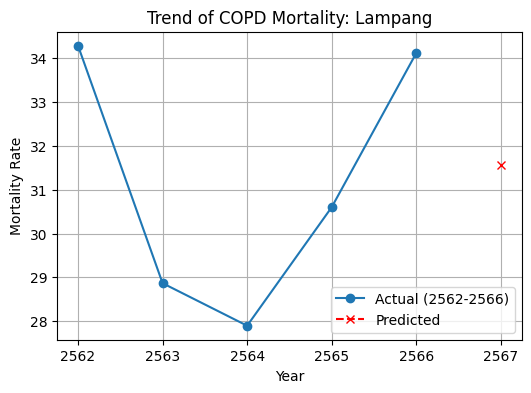

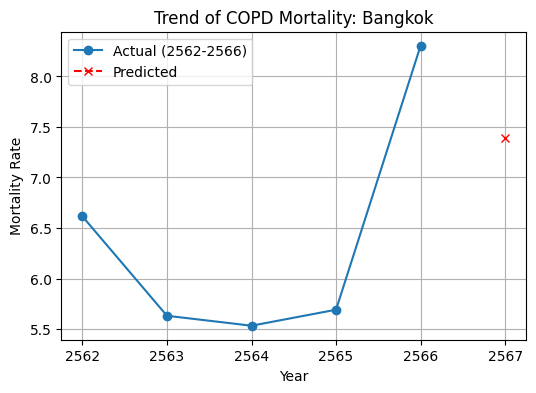

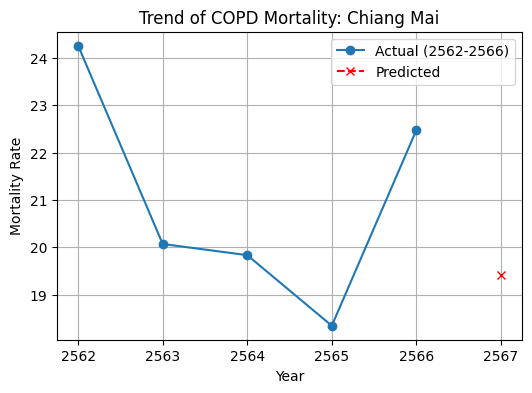

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Step03_Regression_Results.csv")

provinces = ["Lampang", "Bangkok" , "Chiang Mai"]
years = [2562, 2563, 2564, 2565, 2566]

for province in provinces:
    row = df[df["Province"] == province].iloc[0]
    y_values = [row[str(y)] for y in years]
    y_pred = row["Predict"]

    plt.figure(figsize=(6,4))
    plt.plot(years, y_values, marker="o", label="Actual (2562-2566)")
    plt.plot(2567, y_pred, marker="x", color="red", label="Predicted", linestyle="--")
    plt.title(f"Trend of COPD Mortality: {province}")
    plt.xlabel("Year")
    plt.ylabel("Mortality Rate")
    plt.legend()
    plt.grid(True)
    plt.show()

## Step 4: KNN risk-level classification

In [ ]:
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


df_model = pd.read_csv('Step03_Regression_Results.csv')

risk_bins = np.quantile(df_model['Predict'], [0, 0.33, 0.66, 1])
df_model['Risk_Level'] = pd.cut(df_model['Predict'],
                                bins=risk_bins,
                                labels=['Low', 'Medium', 'High'],
                                include_lowest=True)

X = df_model[['Latitude', 'Longitude', 'Predict']]
y = df_model['Risk_Level']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=['Low','Medium','High'])

print("Step 04 Complete: จำแนกระดับความเสี่ยงพื้นที่เรียบร้อยแล้ว")
print(f"Accuracy ของโมเดล KNN: {acc:.4f}")
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report (Precision, Recall, F1-score):")
print(report)

df_model['KNN_Predicted_Risk'] = knn.predict(X)

df_model.to_csv('Step04_KNN_Classification.csv', index=False, encoding='utf-8-sig')

print("\n--- ตัวอย่างข้อมูลที่มีผลลัพธ์ KNN ---")
print(df_model[['Province', 'Predict', 'Risk_Level', 'KNN_Predicted_Risk']].head())

Step 04 Complete: จำแนกระดับความเสี่ยงพื้นที่เรียบร้อยแล้ว
Accuracy ของโมเดล KNN: 0.8750

Confusion Matrix:
[[5 0 1]
 [0 5 1]
 [0 0 4]]

Classification Report (Precision, Recall, F1-score):
              precision    recall  f1-score   support

         Low       1.00      0.83      0.91         6
      Medium       1.00      0.83      0.91         6
        High       0.67      1.00      0.80         4

    accuracy                           0.88        16
   macro avg       0.89      0.89      0.87        16
weighted avg       0.92      0.88      0.88        16


--- ตัวอย่างข้อมูลที่มีผลลัพธ์ KNN ---
     Province    Predict Risk_Level KNN_Predicted_Risk
0     Bangkok   7.042404        Low                Low
1  Chiang Mai  19.935200       High               High
2     Lamphun  18.382284       High               High
3     Lampang  31.431218       High               High
4       Phrae  21.861510       High               High


## Spatial risk map

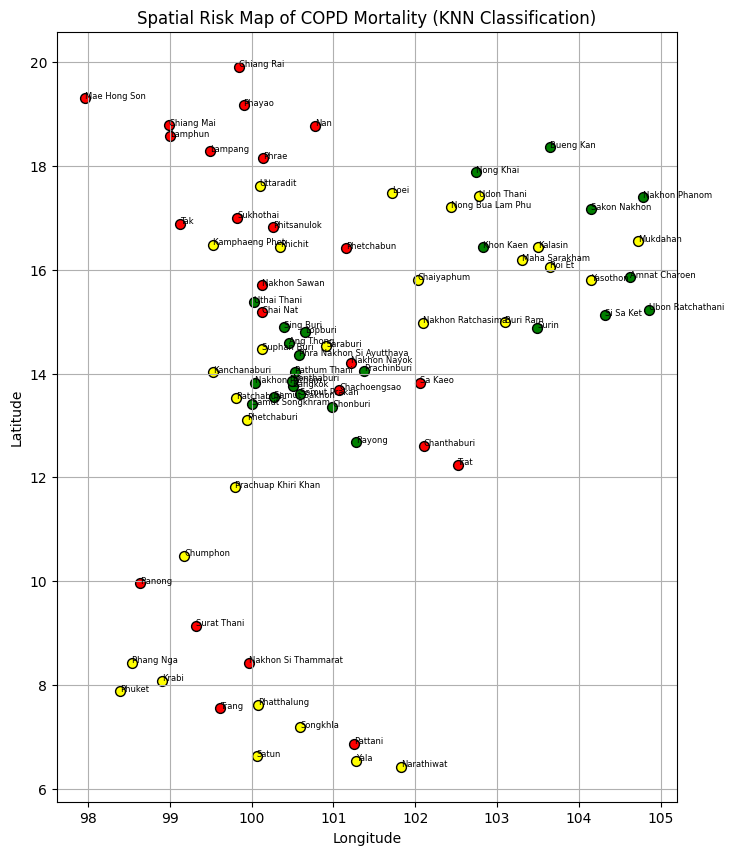

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Step04_KNN_Classification.csv")

color_map = {"High":"red", "Medium":"yellow", "Low":"green"}

plt.figure(figsize=(8,10))
for _, row in df.iterrows():
    plt.scatter(row["Longitude"], row["Latitude"],
                color=color_map[row["KNN_Predicted_Risk"]],
                s=50, edgecolor="black")
    plt.text(row["Longitude"], row["Latitude"], row["Province"], fontsize=6)

plt.title("Spatial Risk Map of COPD Mortality (KNN Classification)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

## KNN confusion matrix

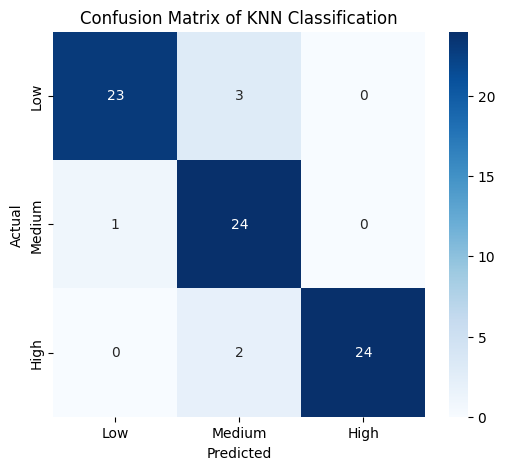

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

df = pd.read_csv("Step04_KNN_Classification.csv")

y_true = df["Risk_Level"]
y_pred = df["KNN_Predicted_Risk"]
labels = ["Low","Medium","High"]

cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)

plt.title("Confusion Matrix of KNN Classification")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()